# Brazilian E-Commerce Analysis

## Project objective
This notebook explores the Brazilian Olist e-commerce dataset. It combines order, customer, product, payment and review information, prepares the data for analysis, creates order-level and review-level datasets, calculates key business metrics, and exports the resulting tables.

The notebook intentionally keeps the consolidated `ecommerce_df`, `order_level_df`, and `review_df` dataframes. The consolidated dataframe is useful for exploration, while the separate order-level summaries help avoid counting product or payment records multiple times when calculating order-level metrics.

## 1. Import libraries and load source data

In [1]:
# Import pandas and NumPy for data manipulation; Matplotlib and Seaborn for visualization.
import pandas as pd,numpy as np
import matplotlib.pyplot as plt,seaborn as sns

### Load the source CSV files

Each CSV represents a different part of the e-commerce business:
- **Customers:** customer identifiers and location details.
- **Order items:** products purchased in each order, including item price and freight.
- **Payments:** payment transactions, payment methods, installments and transaction values.
- **Reviews:** customer review scores and comments.
- **Orders:** order status and purchase/delivery timestamps.
- **Products:** product attributes.
- **Category translation:** Portuguese product category names mapped to English.

The files are read from the notebook's current working directory.

In [2]:
customers = pd.read_csv('olist_customers_dataset.csv')
order_items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
category = pd.read_csv('product_category_name_translation.csv')

## 2. Merge the source datasets

Start with the orders table and attach customer details using `customer_id`. A left join keeps every order even if a matching customer record is missing.

In [3]:
# Start with the orders table and attach customer attributes using the shared customer ID.
df = orders.merge(customers, on='customer_id', how='left')

### Add order-item details

Join `order_items` using `order_id`. Orders containing multiple products will have multiple rows, one for each order item.

In [4]:
df = df.merge(order_items, on='order_id', how='left')

### Add product attributes

Join product information using `product_id` so the merged dataset includes product-level details.

In [5]:
df = df.merge(products, on='product_id', how='left')

### Translate product categories

Join the category translation table using `product_category_name` to add the English category name.

In [6]:
df = df.merge(category, on='product_category_name', how='left')

### Add payment transactions

Join payment records using `order_id`. An order can have more than one payment transaction or payment method, so this join can create multiple rows for an order.

In [7]:
df = df.merge(payments, on='order_id', how='left')

### Add customer reviews

Join review information using `order_id`. The resulting `df` is a consolidated dataset for exploration. Because item, payment and review records are joined at different levels of detail, be careful when summing or counting values in this flattened dataframe.

In [8]:
df = df.merge(reviews, on='order_id', how='left')

### Inspect the merged data

Display the first five rows to check that the joins worked and that the expected columns are present.

In [9]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58


### Review the merged columns

Inspect the column names to understand which order, customer, product, payment and review fields are available after merging.

In [10]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name_english', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value', 'review_id', 'review_score',
       'review_comment_title', 'review_comment_message',
       'review_creation_date', 'review_answer_timestamp'],
      dtype='str')

## 3. Filter and prepare the consolidated dataset

Keep delivered orders for the main analysis. The `.copy()` creates an independent dataframe so later transformations do not unintentionally modify a view of `df`.

In [11]:
# Keep delivered orders for the main analysis and create an independent copy.
ecommerce_df = df[df['order_status'] == 'delivered'].copy()

### Preview delivered orders

Check a sample of the filtered records before removing unnecessary columns or cleaning values.

In [12]:
ecommerce_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58


### Inspect columns before cleaning

Review the available fields and decide which columns are relevant to the planned analysis.

In [13]:
ecommerce_df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_zip_code_prefix', 'customer_city',
       'customer_state', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value',
       'product_category_name', 'product_name_lenght',
       'product_description_lenght', 'product_photos_qty', 'product_weight_g',
       'product_length_cm', 'product_height_cm', 'product_width_cm',
       'product_category_name_english', 'payment_sequential', 'payment_type',
       'payment_installments', 'payment_value', 'review_id', 'review_score',
       'review_comment_title', 'review_comment_message',
       'review_creation_date', 'review_answer_timestamp'],
      dtype='str')

### Remove columns not required for this analysis

Drop detailed review text and identifiers, unused product dimensions, and other fields that are not needed for the current analysis. The English product category, payment method, payment value, review score and core order fields are retained.

In [14]:
ecommerce_df = ecommerce_df.drop(columns=[
    'review_answer_timestamp',
    'review_creation_date',
    'review_comment_message',
    'review_comment_title',
    'review_id',
    'product_category_name',
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm',
    'payment_sequential',
    'customer_zip_code_prefix',
    'seller_id',
    'shipping_limit_date'
])

### Check dataset dimensions

The `shape` attribute returns the number of rows and columns after column selection.

In [15]:
ecommerce_df.shape

(115723, 20)

### Inspect data types and non-null counts

`info()` provides the dataframe structure, column data types, non-null counts and approximate memory usage.

In [16]:
ecommerce_df.info()

<class 'pandas.DataFrame'>
Index: 115723 entries, 0 to 119142
Data columns (total 20 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       115723 non-null  str    
 1   customer_id                    115723 non-null  str    
 2   order_status                   115723 non-null  str    
 3   order_purchase_timestamp       115723 non-null  str    
 4   order_approved_at              115708 non-null  str    
 5   order_delivered_carrier_date   115721 non-null  str    
 6   order_delivered_customer_date  115715 non-null  str    
 7   order_estimated_delivery_date  115723 non-null  str    
 8   customer_unique_id             115723 non-null  str    
 9   customer_city                  115723 non-null  str    
 10  customer_state                 115723 non-null  str    
 11  order_item_id                  115723 non-null  float64
 12  product_id                     115723 non-null

### Convert timestamp columns to datetime

Convert the order purchase, approval, carrier handoff, customer delivery and estimated delivery columns to pandas datetime values. This enables date arithmetic and time-based analysis.

In [17]:
# Convert the selected timestamp columns to datetime so date calculations work correctly.
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_cols:
    ecommerce_df[col] = pd.to_datetime(ecommerce_df[col])

### Verify datetime conversion

Run `info()` again to confirm that the selected timestamp columns now have datetime data types.

In [18]:
ecommerce_df.info()

<class 'pandas.DataFrame'>
Index: 115723 entries, 0 to 119142
Data columns (total 20 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       115723 non-null  str           
 1   customer_id                    115723 non-null  str           
 2   order_status                   115723 non-null  str           
 3   order_purchase_timestamp       115723 non-null  datetime64[us]
 4   order_approved_at              115708 non-null  datetime64[us]
 5   order_delivered_carrier_date   115721 non-null  datetime64[us]
 6   order_delivered_customer_date  115715 non-null  datetime64[us]
 7   order_estimated_delivery_date  115723 non-null  datetime64[us]
 8   customer_unique_id             115723 non-null  str           
 9   customer_city                  115723 non-null  str           
 10  customer_state                 115723 non-null  str           
 11  order_item_id   

### Identify missing values

Count null values in each column and sort the results from highest to lowest to identify fields that may need cleaning.

In [19]:
ecommerce_df.isnull().sum().sort_values(ascending=False)

product_category_name_english    1661
review_score                      861
order_approved_at                  15
order_delivered_customer_date       8
payment_installments                3
payment_type                        3
payment_value                       3
order_delivered_carrier_date        2
order_purchase_timestamp            0
order_status                        0
customer_id                         0
order_id                            0
order_item_id                       0
customer_state                      0
customer_city                       0
customer_unique_id                  0
order_estimated_delivery_date       0
freight_value                       0
product_id                          0
price                               0
dtype: int64

### Investigate missing customer delivery dates

Display records where the actual customer delivery timestamp is missing. Inspect these rows before deciding how to handle them.

In [20]:
ecommerce_df[ecommerce_df['order_delivered_customer_date'].isnull()]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,order_item_id,product_id,price,freight_value,product_category_name_english,payment_type,payment_installments,payment_value,review_score
3582,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18,13467e882eb3a701826435ee4424f2bd,cerquilho,SP,1.0,a50acd33ba7a8da8e9db65094fa990a4,117.30,17.53,auto,credit_card,3.0,134.83,5.0
24665,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16,2f17c5b324ad603491521b279a9ff4de,quadra,SP,1.0,2167c8f6252667c0eb9edd51520706a1,329.00,25.24,industry_commerce_and_business,debit_card,1.0,354.24,5.0
52543,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30,1bd06a0c0df8b23dacfd3725d2dc0bb9,pindamonhangaba,SP,1.0,e7d5464b94c9a5963f7c686fc80145ad,139.00,19.07,watches_gifts,credit_card,3.0,158.07,5.0
94802,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30,3bc508d482a402715be4d5cf4020cc81,sumare,SP,1.0,e7d5464b94c9a5963f7c686fc80145ad,139.00,19.07,watches_gifts,credit_card,1.0,158.07,5.0
99103,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24,ebf7e0d43a78c81991a4c59c145c75db,sao carlos,SP,1.0,ec165cd31c50585786ffda6feff5d0a6,188.99,15.63,toys,credit_card,4.0,204.62,5.0
110904,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23,d77cf4be2654aa70ef150f8bfec076a6,porto alegre,RS,1.0,30b5b5635a79548a48d04162d971848f,179.00,15.00,sports_leisure,credit_card,4.0,194.00,5.0
116933,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26,cce5e8188bf42ffb3bb5b18ff58f5965,guarulhos,SP,1.0,a2a7efc985315e86d4f0f705701b342b,110.99,9.13,computers_accessories,credit_card,5.0,120.12,1.0
117395,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19,175378436e2978be55b8f4316bce4811,ribeirao pires,SP,1.0,55bfa0307d7a46bed72c492259921231,45.90,9.07,books_general_interest,credit_card,1.0,54.97,5.0


### Handle missing product categories

Fill missing English category values with `unknown`. This preserves the records while making missing category information explicit.

In [21]:
ecommerce_df['product_category_name_english'] = (ecommerce_df['product_category_name_english'].fillna('unknown'))

### Remove records missing required fields

Drop rows missing approval, delivery, payment or carrier handoff information. These fields are needed for the analyses that follow. This step removes incomplete records rather than imputing values for them.

In [22]:
ecommerce_df = ecommerce_df.dropna(subset=[
    'order_approved_at',
    'order_delivered_customer_date',
    'payment_value',
    'payment_installments',
    'payment_type',
    'order_delivered_carrier_date'
])

### Check repeated order identifiers

Count how many rows have an `order_id` that appeared earlier. This is a diagnostic check: multiple rows per order can be expected when an order has multiple items or payment transactions.

In [23]:
ecommerce_df['order_id'].duplicated().sum()

np.int64(19242)

### Remove exact duplicate rows

`drop_duplicates()` removes rows that are identical across all retained columns. It does not force one row per order; distinct item or payment records remain.

In [24]:
ecommerce_df = ecommerce_df.drop_duplicates()

### Recheck orders with multiple rows

Display all rows belonging to duplicated order IDs. This helps inspect whether the remaining rows represent different items or payment transactions rather than exact duplicates.

In [25]:
ecommerce_df[ecommerce_df['order_id'].duplicated(keep=False)]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,customer_state,order_item_id,product_id,price,freight_value,product_category_name_english,payment_type,payment_installments,payment_value,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,29.99,8.72,housewares,credit_card,1.0,18.12,4.0
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,29.99,8.72,housewares,voucher,1.0,2.00,4.0
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,sao paulo,SP,1.0,87285b34884572647811a353c7ac498a,29.99,8.72,housewares,voucher,1.0,18.59,4.0
11,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,299905e3934e9e181bfb2e164dd4b4f8,sorocaba,SP,1.0,9a78fb9862b10749a117f7fc3c31f051,149.99,19.77,office_furniture,voucher,1.0,161.42,5.0
12,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,299905e3934e9e181bfb2e164dd4b4f8,sorocaba,SP,1.0,9a78fb9862b10749a117f7fc3c31f051,149.99,19.77,office_furniture,credit_card,1.0,8.34,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119133,9115830be804184b91f5c00f6f49f92d,da2124f134f5dfbce9d06f29bdb6c308,delivered,2017-10-04 19:57:37,2017-10-04 20:07:14,2017-10-05 16:52:52,2017-10-20 20:25:45,2017-11-07,c716cf2b5b86fb24257cffe9e7969df8,cuiaba,MT,2.0,49d2e2460386273b195e7e59b43587c3,26.90,36.98,toys,voucher,1.0,64.37,5.0
119134,aa04ef5214580b06b10e2a378300db44,f01a6bfcc730456317e4081fe0c9940e,delivered,2017-01-27 00:30:03,2017-01-27 01:05:25,2017-01-30 11:40:16,2017-02-07 13:15:25,2017-03-17,e03dbdf5e56c96b106d8115ac336f47f,divinopolis,MG,1.0,9fc063fd34fed29ccc57b7f8e8d03388,370.00,19.43,health_beauty,voucher,1.0,250.00,5.0
119135,aa04ef5214580b06b10e2a378300db44,f01a6bfcc730456317e4081fe0c9940e,delivered,2017-01-27 00:30:03,2017-01-27 01:05:25,2017-01-30 11:40:16,2017-02-07 13:15:25,2017-03-17,e03dbdf5e56c96b106d8115ac336f47f,divinopolis,MG,1.0,9fc063fd34fed29ccc57b7f8e8d03388,370.00,19.43,health_beauty,credit_card,5.0,139.43,5.0
119140,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15,5097a5312c8b157bb7be58ae360ef43c,japuiba,RJ,1.0,d1c427060a0f73f6b889a5c7c61f2ac4,179.99,40.59,computers_accessories,credit_card,4.0,441.16,2.0


### Create an explicit working copy

Create a separate copy of the cleaned dataframe before adding calculated columns.

In [26]:
ecommerce_df = ecommerce_df.copy()

### Calculate delivery duration

Calculate the number of calendar days between purchase and actual customer delivery. The result is stored in `delivery_days`.

In [27]:
# Calendar days from purchase to actual customer delivery.
ecommerce_df['delivery_days'] = (
    ecommerce_df['order_delivered_customer_date'] - 
    ecommerce_df['order_purchase_timestamp']
).dt.days

### Calculate delivery delay against the estimate

Subtract the estimated delivery date from the actual delivery date. Positive values indicate delivery after the estimate; negative values indicate delivery before the estimate; zero means delivery on the estimated date.

In [28]:
# Positive = late; negative = early; zero = delivered on the estimated date.
ecommerce_df['delivery_delay'] = (
    ecommerce_df['order_delivered_customer_date'] - 
    ecommerce_df['order_estimated_delivery_date']
).dt.days

### Extract purchase year and month

Create `purchase_year` and `purchase_month` from the purchase timestamp. These fields can be used for yearly and monthly trend analysis.

In [29]:
ecommerce_df['purchase_year'] = ecommerce_df['order_purchase_timestamp'].dt.year
ecommerce_df['purchase_month'] = ecommerce_df['order_purchase_timestamp'].dt.month_name()

## 4. Create order-level and review-level datasets

Create `order_level_df` with one representative row per order. This is useful for order-level metrics, but because the consolidated dataframe contains multiple item/payment rows, the row retained by `drop_duplicates()` should not be used by itself to calculate total item revenue or total payment value. Those totals are calculated from the original source tables below.

In [30]:
# Retain one row per order; calculate item and payment totals separately from source tables below.
order_level_df = ecommerce_df.drop_duplicates(subset =['order_id'])

### Aggregate item and payment values at order level

The order-items table can contain several products per order, and the payments table can contain several transactions per order. Aggregate each source separately by `order_id` before joining the summaries to the one-row-per-order dataframe. This avoids multiplying item rows by payment rows.

### Correct order-level aggregations

The consolidated `ecommerce_df` is retained for your existing analysis. Because an order can contain multiple items and multiple payment transactions, calculate item totals and payment totals from their original tables before using them in order-level metrics.

### Build review-level data

Create `review_df` by keeping orders with a non-missing review score. Since this is derived from `order_level_df`, it retains one row per order for the review-score analysis.

In [31]:
# Calculate item and freight totals for each delivered order
item_summary = (
    order_items[order_items['order_id'].isin(order_level_df['order_id'])]
    .groupby('order_id', as_index=False)
    .agg(
        total_item_price=('price', 'sum'),
        total_freight_value=('freight_value', 'sum')
    )
)

# Add all payment transactions for each order
payment_summary = (
    payments[payments['order_id'].isin(order_level_df['order_id'])]
    .groupby('order_id', as_index=False)
    .agg(
        total_payment_value=('payment_value', 'sum'),
        payment_transaction_count=('payment_sequential', 'count')
    )
)

# Keep your existing order_level_df and enrich it with accurate totals
order_level_df = order_level_df.merge(item_summary, on='order_id', how='left')
order_level_df = order_level_df.merge(payment_summary, on='order_id', how='left')

### Check for repeated order-item combinations

Check whether the combination of `order_id`, `product_id` and `order_item_id` appears more than once. Any returned rows should be inspected to determine whether they are genuine duplicates.

In [32]:
# Keep only orders that have a recorded review score.
review_df = order_level_df.dropna(subset = ['review_score'])

## 5. Key business metrics

### Total item revenue

Sum `total_item_price`, which was calculated by summing all item prices from the original `order_items` table for each delivered order. This avoids losing additional products when creating a one-row-per-order dataframe.

In [33]:
order_level_df[
    order_level_df.duplicated(
        subset=['order_id', 'product_id', 'order_item_id'],
        keep=False
    )
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_city,...,payment_value,review_score,delivery_days,delivery_delay,purchase_year,purchase_month,total_item_price,total_freight_value,total_payment_value,payment_transaction_count


### Average delivery time

Calculate the average number of days between purchase and customer delivery using `delivery_days`. The result is rounded to a whole number of days.

In [34]:
print(f"Total Revenue : {order_level_df['total_item_price'].sum():,.2f}")

Total Revenue : 13,218,264.53


### Most popular product categories

Count category occurrences and display the ten most frequent categories. This uses the consolidated dataframe; remember that the merged data can contain repeated order-level records.

In [35]:
print(f"Average Delivery Time : {ecommerce_df['delivery_days'].mean().round(0)}")

Average Delivery Time : 12.0


### Payment method counts in the consolidated data

This displays payment-type counts from `ecommerce_df`. Because the consolidated dataset can repeat payment rows when an order has multiple items, these counts may be inflated. Use the original `payments` table for transaction-level payment method analysis, as shown in the next cell.

In [36]:
print(f"Most Popular Categories : {ecommerce_df['product_category_name_english'].value_counts().head(10)}")

Most Popular Categories : product_category_name_english
bed_bath_table           11626
health_beauty             9717
sports_leisure            8689
furniture_decor           8567
computers_accessories     7917
housewares                7131
watches_gifts             6044
telephony                 4572
garden_tools              4447
auto                      4272
Name: count, dtype: int64


### Payment method distribution from the original payments table

First obtain the delivered order IDs, then filter the original payments table to those orders. `value_counts()` counts payment transactions by method. An order that used more than one method contributes a transaction to each relevant payment type.

In [37]:
print(f"Most Common Payment Method : {ecommerce_df['payment_type'].value_counts()}")

Most Common Payment Method : payment_type
credit_card    85056
boleto         22403
voucher         5501
debit_card      1654
Name: count, dtype: int64


### Review score distribution

Count the frequency of each review score and sort by score. For an order-level review distribution, use `review_df` so each order is represented once. The current expression uses `ecommerce_df`, where merged rows can repeat a review score.

In [38]:
# Payment method distribution from original payment transactions for delivered orders
delivered_order_ids = order_level_df['order_id'].unique()
payments[payments['order_id'].isin(delivered_order_ids)]['payment_type'].value_counts()

payment_type
credit_card    74578
boleto         19177
voucher         5493
debit_card      1485
Name: count, dtype: int64

### Visualize review scores

Create a bar chart showing the frequency of each review score. The chart uses the consolidated dataframe in the existing code; for an order-level chart without repeated review rows, use `review_df['review_score'].value_counts().sort_index()` instead.

In [39]:
print(f"Revie Score Distribution : {ecommerce_df['review_score'].value_counts().sort_index()}")

Revie Score Distribution : review_score
1.0    12996
2.0     3866
3.0     9579
4.0    21953
5.0    65362
Name: count, dtype: int64


## 6. Export analysis datasets

Save the prepared dataframes as CSV files. These files can be used in SQL or Power BI without having to repeat the Python cleaning and preparation steps.

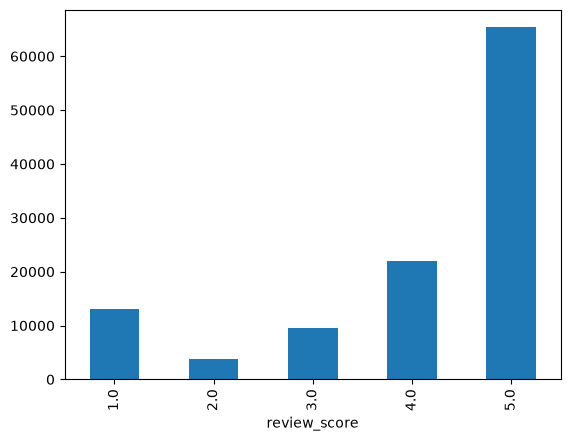

In [40]:
import matplotlib.pyplot as plt

ecommerce_df['review_score'].value_counts().sort_index().plot(kind='bar')

plt.show()

### Export the consolidated e-commerce dataset

Save `ecommerce_df`, which contains the cleaned delivered-order records and the calculated delivery and purchase date fields.

In [41]:
ecommerce_df.to_csv('ecommerce_data.csv', index=False)

### Export the order-level dataset

Save `order_level_df`, which contains one row per order plus the aggregated item and payment metrics. This is the appropriate export for order-level analysis.

In [42]:
order_level_df.to_csv('order_level_data.csv', index=False)

### Export the review dataset

Save `review_df`, which contains the orders with an available review score.

In [43]:
review_df.to_csv('review_data.csv', index=False)

## End of notebook

The three prepared datasets are now available as CSV files for downstream SQL and Power BI analysis.

In [44]:
(order_level_df['total_item_price'] +
 order_level_df['total_freight_value']).sum()

np.float64(15416102.79)

In [45]:
# Keep only delivered orders
delivered_order_ids = order_level_df['order_id'].unique()

# Merge order items with product details
category_df = order_items[
    order_items['order_id'].isin(delivered_order_ids)
].merge(
    products[['product_id', 'product_category_name']],
    on='product_id',
    how='left'
)

# Add English category names
category_df = category_df.merge(
    category,
    on='product_category_name',
    how='left'
)

category_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [46]:
category_revenue = (
    category_df.groupby('product_category_name_english')
    .agg(
        Total_Products_Sold=('order_item_id', 'count'),
        Total_Revenue=('price', 'sum'),
        Total_Freight=('freight_value', 'sum')
    )
    .reset_index()
    .sort_values('Total_Revenue', ascending=False)
)

category_revenue.head(10)

,product_category_name_english,Total_Products_Sold,Total_Revenue,Total_Freight
43,health_beauty,9462,1232996.75,178949.32
70,watches_gifts,5857,1165898.98,98118.00
7,bed_bath_table,10952,1023300.77,201751.30
65,sports_leisure,8428,954604.57,163363.88
15,computers_accessories,7643,888613.62,143990.03
39,furniture_decor,8156,711493.09,168341.94
49,housewares,6795,615628.69,142763.56
20,cool_stuff,3715,609964.13,81407.38
5,auto,4139,578849.35,90470.57
69,toys,4029,471097.49,75758.95


In [47]:
category_revenue.to_csv('category_revenue.csv', index=False)